# Analyzing Airport Networks: Graph Basics and Preprocessing (Participant 3)

**Question:** How large and sparse is the network, and how does cleaning change it?

**Graph-theory topics:** simple, multi and mixed graphs; directed versus undirected graphs;
self-loops; vertex degree and the handshaking theorem; adjacency matrix and graph density;
subgraphs; weak and strong connectivity.

**Learning outcome:** this report explains how the cleaned flight graph is built. It measures the size,
density and degree distribution of the graph. It also justifies each cleaning decision.

*How to run:* the data is read from `../data/`, because this notebook lives in `notebooks/`.
Dependencies are listed in `pyproject.toml`.

*Reference:* data from OpenFlights `routes.dat` and `airports.dat`.

---
## 1. Data and cleaning

This report uses one main file, `routes.dat`. Each row states that an airline lists a flight from a
source airport (`src`) to a destination airport (`dst`). The file `airports.dat` is used only to add
airport names and countries in section 9.

We keep three columns: `src`, `dst` and `airline`. These are enough to build the graph. Notebook **01_context_and_data.ipynb**
describes the other columns.

OpenFlights writes missing values as `\N`. We tell pandas to read them as missing (`na_values="\\N"`).


In [1]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from collections import defaultdict

DATA = "../data"

route_cols = ["airline", "airline_id", "src", "src_id", "dst", "dst_id",
              "codeshare", "stops", "equipment"]
airport_cols = ["airport_id", "name", "city", "country", "iata", "icao", "lat", "lon",
                "altitude", "utc_offset", "dst_rule", "tz", "type", "source"]

def load(file, cols):
    return pd.read_csv(f"{DATA}/{file}", header=None, names=cols,
                       na_values="\\N", keep_default_na=False)

routes_raw = load("routes.dat", route_cols)
airports = load("airports.dat", airport_cols)       # used only for airport names in section 9
routes_raw.shape

(67663, 9)


**Cleaning versus pruning.** Two kinds of change are kept apart in this report.

| | Cleaning | Pruning |
|---|---|---|
| Aim | fix errors so that the graph is correct | remove valid data for a specific goal |
| Examples | drop rows with missing or invalid airport codes; merge duplicate edges; remove self-loops | remove low-degree vertices; keep the largest component; filter edges by weight |
| Rule | apply when the model needs it | apply only with a reason, and test the effect first |
| Where | sections 1, 2 and 5 | section 10.2 |

Each step is documented, and the counts before and after it are recorded. Section 10.1 collects them in
one table.


### 1.1 Dropping invalid rows

*Purpose:* remove rows that cannot become an edge. An edge needs a source, a destination and an airline.
Each airport code must also be a valid 3-character code. We count first, then drop.

In [2]:
key_cols = ["src", "dst", "airline"]
log = []                                   # cleaning log: counts before and after each step (section 10.1)

def n_vert(df):
    return len(set(df["src"]) | set(df["dst"]))

print("Missing values per key column:")
print(routes_raw[key_cols].isna().sum().to_string())
routes = routes_raw.dropna(subset=key_cols)[key_cols]
log.append(("1.1 drop rows with missing keys", "rows", len(routes_raw), len(routes), n_vert(routes_raw), n_vert(routes)))

valid_code = r"^[A-Z0-9]{3}$"              # IATA style airport code
ok = routes["src"].str.match(valid_code) & routes["dst"].str.match(valid_code)
print(f"\nRows with an invalid airport code: {(~ok).sum():,}")
rows_before, v_before = len(routes), n_vert(routes)
routes = routes[ok]
log.append(("1.1 drop rows with invalid codes", "rows", rows_before, len(routes), v_before, n_vert(routes)))

print(f"Duplicate rows (same src, dst and airline): {routes.duplicated().sum():,}")
rows_before, v_before = len(routes), n_vert(routes)
routes = routes.drop_duplicates()
log.append(("1.1 drop duplicate rows", "rows", rows_before, len(routes), v_before, n_vert(routes)))

print(f"\nRows before: {len(routes_raw):,} | rows after: {len(routes):,} | dropped: {len(routes_raw) - len(routes):,}")

Missing values per key column:
src        0
dst        0
airline    0

Rows with an invalid airport code: 0
Duplicate rows (same src, dst and airline): 0

Rows before: 67,663 | rows after: 67,663 | dropped: 0


**Takeaway:** no row has a missing key, an invalid code or a duplicate listing, so nothing is dropped.
We keep the checks as a safety step.

### 1.2 Vertices

*Purpose:* define the vertices as the airports that appear as a source or a destination.

In [3]:
vertices = set(routes["src"]) | set(routes["dst"])
print(f"Airports in routes.dat (vertices |V|): {len(vertices):,}")
print(f"Airports listed in airports.dat:       {len(airports):,}")

Airports in routes.dat (vertices |V|): 3,425
Airports listed in airports.dat:       7,698


**Takeaway:** the graph has **3,425 vertices**. Most airports in `airports.dat` never appear in a route,
so they are not vertices.

---
## 2. Graph models built

Two graphs are built from the same rows.

| Name | Type | One edge per | Airline is stored as |
|---|---|---|---|
| `MG` | `MultiDiGraph` | (src, dst, airline) | the edge key |
| `G` | `DiGraph` (simple) | (src, dst) | a `frequency` set on the edge |

`MG` keeps every airline listing. `G` merges parallel edges into one. The `frequency` attribute is the
**set of airlines** on that route. Its size is the number of airlines, not the number of flights.

*Purpose:* build `MG` and `G`. The merge from `MG` to `G` is a modelling step. It removes no airline
information, because every airline stays in `frequency`.

In [4]:
MG = nx.MultiDiGraph()
for row in routes.itertuples(index=False):
    MG.add_edge(row.src, row.dst, key=row.airline)     # the airline is the edge key

G = nx.DiGraph()
for u, v, airline in MG.edges(keys=True):
    if G.has_edge(u, v):
        G[u][v]["frequency"].add(airline)               # same route, another airline
    else:
        G.add_edge(u, v, frequency={airline})

before = {"MG edges": MG.number_of_edges(), "G edges": G.number_of_edges(),
          "vertices": G.number_of_nodes(), "density": nx.density(G)}   # saved for section 10
log.append(("2 merge parallel edges (MG to G)", "edges", MG.number_of_edges(), G.number_of_edges(),
            MG.number_of_nodes(), G.number_of_nodes()))

pd.DataFrame({
    "vertices": [MG.number_of_nodes(), G.number_of_nodes()],
    "edges": [MG.number_of_edges(), G.number_of_edges()],
}, index=["MG (multi, directed)", "G (simple, directed)"])

,vertices,edges
"MG (multi, directed)",3425,67663
"G (simple, directed)",3425,37595


**Takeaway:** both graphs have 3,425 vertices. `MG` has 67,663 edges and `G` has 37,595. The gap comes
from the parallel edges. Both graphs still hold one self-loop (section 5).

---
## 3. Simple, multi and mixed graphs



### 3.1 Multigraph and Simple graph
Several airlines can serve the same route. So `MG` has **parallel edges**: more than one edge for the
same ordered pair of airports. Some of them come from codeshare listings (see Participant 1).

A simple graph has no parallel edges. `G` is simple: the parallel edges of `MG` are collapsed into one edge and the airlines are kept as an attribute. The ordered pairs `u -> v` and `v -> u` are different, so a simple *directed* graph may hold both.

*Purpose:* show one example route and find the route with the most parallel edges.

In [5]:
print("Airlines on FRU -> OSS:", sorted(MG["FRU"]["OSS"]))
print("Edges in MG:", f"{MG.number_of_edges():,}", "| edges in G:", f"{G.number_of_edges():,}")

u, v = max(G.edges, key=lambda e: len(G.edges[e]["frequency"]))
print(f"Most parallel edges: {u} -> {v}, listed by {len(G.edges[u, v]['frequency'])} airlines")

Airlines on FRU -> OSS: ['QH', 'YK', 'ZM']
Edges in MG: 67,663 | edges in G: 37,595
Most parallel edges: ORD -> ATL, listed by 20 airlines


**Takeaway:** the route FRU -> OSS is served by 3 airlines, so `MG` holds 3 parallel edges for it. The
route ORD -> ATL has the most, with 20 airlines. `G` merges them into one edge per route.



### 3.2 Mixed graph view
A mixed graph has both undirected edges and directed arcs. `G` can be viewed this way:

* if both `u -> v` and `v -> u` exist, they are treated as **one undirected edge**;
* if only one direction exists, it stays a **one-way arc**.

*Purpose:* count the two kinds of edge, and list the airports that only send or only receive flights.

In [6]:
two_way = sum(1 for u, v in G.edges if u != v and G.has_edge(v, u)) // 2    # each pair is seen twice
one_way = sum(1 for u, v in G.edges if u != v and not G.has_edge(v, u))

print(f"Two-way pairs (undirected edges): {two_way:,}")
print(f"One-way arcs:                     {one_way:,}")
print(f"Arcs that have a return arc:      {2 * two_way / (2 * two_way + one_way):.1%}")

out_only = sorted(v for v in G if G.in_degree(v) == 0)     # departures only
in_only = sorted(v for v in G if G.out_degree(v) == 0)     # arrivals only
print(f"\nAirports with only outgoing flights ({len(out_only)}): {out_only}")
print(f"Airports with only incoming flights ({len(in_only)}): {in_only}")

Two-way pairs (undirected edges): 18,338
One-way arcs:                     918
Arcs that have a return arc:      97.6%

Airports with only outgoing flights (7): ['IUE', 'LJA', 'MSW', 'PTJ', 'STZ', 'SXX', 'VDA']
Airports with only incoming flights (16): ['BSS', 'BVS', 'CMP', 'CZJ', 'DLZ', 'FMI', 'KPR', 'KYK', 'KZB', 'KZI', 'MTE', 'ORX', 'QFX', 'SPI', 'TUA', 'UII']


**Takeaway:** most routes are two-way (18,338 pairs). Only 918 are one-way arcs. The 7 start-only and
16 end-only airports most likely reflect gaps in the data, because aircraft must return.

---
## 4. Directed versus undirected

**Decision:** we keep `G` **directed**. A flight is a one-way event. It leaves one airport and arrives at
another. The 918 one-way arcs show why. They have no return route in the data, and an undirected graph
would hide that.

An undirected graph is enough to ask *whether* airports are linked, because 97.6% of arcs have a return
arc. A directed graph also answers whether a traveller can fly somewhere *and back* (strong components,
section 9).

The undirected projection, `G.to_undirected()`, is used only where direction does not matter. One
example is the handshaking check in section 6.

*Purpose:* inspect a few one-way arcs. An undirected graph would draw them as normal links.

In [7]:
one_way_arcs = [(u, v) for u, v in G.edges if u != v and not G.has_edge(v, u)]
pd.DataFrame(one_way_arcs, columns=["src", "dst"]).head(5)

,src,dst
0,TAS,MXP
1,KRR,IST
2,KRR,SKG
3,DME,KQT
4,IST,JRO



**Takeaway:** these arcs have no return arc in the data, so the direction carries information.


---
## 5. Self-loops

A **self-loop** is an edge from a vertex to itself.

*Purpose:* find every self-loop in both graphs.

In [8]:
loops_mg = list(nx.selfloop_edges(MG, keys=True))
loops_g = list(nx.selfloop_edges(G))
loop_node = loops_g[0][0]                      # the vertex that holds the loop
before["loop degree"] = G.degree(loop_node)    # saved for section 10

print("Self-loops in MG:", loops_mg)
print("Self-loops in G: ", loops_g)
print(f"{loop_node} total degree with the loop:", G.degree(loop_node))

Self-loops in MG: [('PKN', 'PKN', 'IL')]
Self-loops in G:  [('PKN', 'PKN')]
PKN total degree with the loop: 14


**Why we remove it:** a flight from an airport to itself joins no two airports, so it is not a
connection. We treat it as a data anomaly. It adds 1 to the in-degree and 1 to the out-degree of PKN, so
PKN looks better connected than it is. It is 1 row out of 67,663.

This is a **cleaning** step, not pruning. Many metrics used in this project assume a simple graph
without loops, such as clustering, triangle counts and PageRank. The loop is removed from **both** graphs,
so `MG` and `G` stay consistent.

*Purpose:* remove the self-loop from both graphs and log the counts.

In [9]:
mg_before, g_before = MG.number_of_edges(), G.number_of_edges()
MG.remove_edges_from(loops_mg)
G.remove_edges_from(loops_g)
log.append(("5 remove self-loops (MG)", "edges", mg_before, MG.number_of_edges(), MG.number_of_nodes(), MG.number_of_nodes()))
log.append(("5 remove self-loops (G)", "edges", g_before, G.number_of_edges(), G.number_of_nodes(), G.number_of_nodes()))

print("MG edges:", f"{MG.number_of_edges():,}", "| G edges:", f"{G.number_of_edges():,}")
print(f"{loop_node} total degree after removal:", G.degree(loop_node))
print("Self-loops left:", nx.number_of_selfloops(MG) + nx.number_of_selfloops(G))

MG edges: 67,662 | G edges: 37,594
PKN total degree after removal: 12
Self-loops left: 0


**Takeaway:** `MG` now has 67,662 edges and `G` has 37,594. This is the only edge removed in cleaning.

---
## 6. Handshaking theorem

In an undirected graph, the sum of all degrees is $2|E|$. Each edge adds 1 to the degree of both its
ends. In a directed graph, the sum of in-degrees equals the sum of out-degrees, and both equal $|E|$.

*Purpose:* use the theorem as a **check** of the graph build. If the sums did not match, the build would
contain a bug.

In [10]:
E = G.number_of_edges()
sum_in = sum(d for _, d in G.in_degree())
sum_out = sum(d for _, d in G.out_degree())
print(f"Directed:   sum(in) = {sum_in:,} | sum(out) = {sum_out:,} | |E| = {E:,}")
assert sum_in == sum_out == E

G_und = G.to_undirected()          # undirected projection: a two-way pair becomes one edge
E_und = G_und.number_of_edges()
sum_deg = sum(d for _, d in G_und.degree())
print(f"Undirected: sum(deg) = {sum_deg:,} | 2|E| = {2 * E_und:,} (|E| = {E_und:,} = {two_way:,} two-way pairs + {one_way:,} one-way arcs)")
assert sum_deg == 2 * E_und

Directed:   sum(in) = 37,594 | sum(out) = 37,594 | |E| = 37,594
Undirected: sum(deg) = 38,512 | 2|E| = 38,512 (|E| = 19,256 = 18,338 two-way pairs + 918 one-way arcs)


**Takeaway:** both forms hold, so the degrees and edge counts are consistent.

---
## 7. Adjacency matrix, density and degree


### 7.1 Adjacency matrix
The adjacency matrix $A$ has one row and one column per airport. $A_{ij} = 1$ if there is an arc $i \to j$, and $0$ if not.

*Purpose:* build $A$ and measure how empty it is. A **sparse** matrix is used, because almost all cells are zero and a dense matrix would store every one of them.

In [11]:
nodes = sorted(G.nodes)
A = nx.to_scipy_sparse_array(G, nodelist=nodes, weight=None, format="csr")
n = A.shape[0]

print("Shape:", A.shape)
print(f"Cells: {n * n:,} | non-zero: {A.nnz:,}")
print(f"Density = non-zero / n(n-1) = {A.nnz / (n * (n - 1)):.2%}   (nx.density(G) = {nx.density(G):.2%})")

# row sums are out-degrees, column sums are in-degrees
print("Row sums = out-degree:", np.array_equal(A.sum(axis=1), [G.out_degree(v) for v in nodes]))
print("Column sums = in-degree:", np.array_equal(A.sum(axis=0), [G.in_degree(v) for v in nodes]))

Shape: (3425, 3425)
Cells: 11,730,625 | non-zero: 37,594
Density = non-zero / n(n-1) = 0.32%   (nx.density(G) = 0.32%)
Row sums = out-degree: True
Column sums = in-degree: True


**Takeaway:** $A$ is 3,425 x 3,425 with 37,594 non-zero cells. The density is **0.32%**, so the network is very sparse and the sparse format is the right choice.

### 7.2 Degree sequence and distribution
In a directed graph, NetworkX gives **total degree = in-degree + out-degree**. A two-way route counts twice, once in each direction.

*Purpose:* describe the degree sequence. The **median** and the **mean** show whether a few airports pull the average up. The cut-offs of 3 and 5, and the top-share figures, show how uneven the degrees are.

In [12]:
deg = pd.Series(dict(G.degree()))          # total degree = in + out
print(f"Median total degree: {deg.median():.0f} | mean: {deg.mean():.1f} | max: {deg.max()} | min: {deg.min()}")
for t in (3, 5):
    print(f"Share of airports with total degree under {t}: {(deg < t).mean():.1%}")

ranked = deg.sort_values(ascending=False)
for share in (0.01, 0.10, 0.50):
    k = int(len(ranked) * share)
    print(f"Top {share:.0%} of airports ({k:,}) hold {ranked.iloc[:k].sum() / ranked.sum():.1%} of all degree")
deg.describe().round(1)

Median total degree: 6 | mean: 22.0 | max: 477 | min: 1
Share of airports with total degree under 3: 25.9%
Share of airports with total degree under 5: 45.6%
Top 1% of airports (34) hold 15.4% of all degree
Top 10% of airports (342) hold 62.7% of all degree
Top 50% of airports (1,712) hold 93.0% of all degree


count    3425.0
mean       22.0
std        48.3
min         1.0
25%         2.0
50%         6.0
75%        16.0
max       477.0
dtype: float64


*Purpose:* show the shape of the distribution. The left panel zooms in on degrees 0 to 60 and adds the cumulative curves. The right panel uses log-log axes.


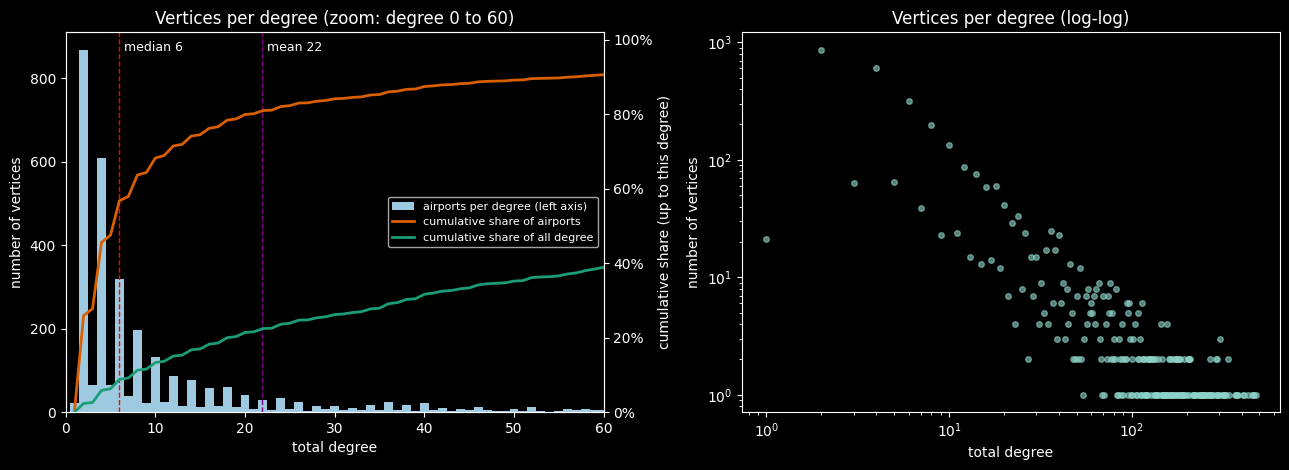

In [56]:
counts = deg.value_counts().sort_index()           # how many airports have each degree
cum_airports = counts.cumsum() / counts.sum()                    # share of airports with degree <= x
cum_degree = pd.Series((counts.index.to_numpy() * counts.values).cumsum() / deg.sum(), index=counts.index) # share of all degree held by those airports

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].bar(counts.index, counts.values, width=1.0, color="#9ecae1", label="airports per degree (left axis)")
axes[0].set_xlim(0, 60)
axes[0].set(title="Vertices per degree (zoom: degree 0 to 60)",
            xlabel="total degree", ylabel="number of vertices")
axes[0].axvline(deg.median(), color="r", ls="--", lw=1)
axes[0].axvline(deg.mean(), color="purple", ls="--", lw=1)
axes[0].text(deg.median() + 0.5, axes[0].get_ylim()[1] * 0.95, f"median {deg.median():.0f}", fontsize=9)
axes[0].text(deg.mean() + 0.5, axes[0].get_ylim()[1] * 0.95, f"mean {deg.mean():.0f}", fontsize=9)

ax2 = axes[0].twinx()                                            # cumulative curves, right axis
ax2.plot(cum_airports.index, cum_airports.values, color="#d95f02", lw=2, label="cumulative share of airports")
ax2.plot(cum_degree.index, cum_degree.values, color="#1b9e77", lw=2, label="cumulative share of all degree")
ax2.set_ylim(0, 1.02)
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax2.set_ylabel("cumulative share (up to this degree)")
h1, l1 = axes[0].get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax2.legend(h1 + h2, l1 + l2, loc="center right", fontsize=8)

axes[1].loglog(counts.index, counts.values, "o", ms=4, alpha=0.6)
axes[1].set(title="Vertices per degree (log-log)",
            xlabel="total degree", ylabel="number of vertices")
plt.tight_layout()
plt.savefig("fig_p3_degree_distribution.png", dpi=150)
plt.show()

*Purpose:* show the complete bar chart over the full span of degrees, from 0 to the maximum of 477. The zoomed panel above hides the hubs. The blue dashed line marks degree 250.


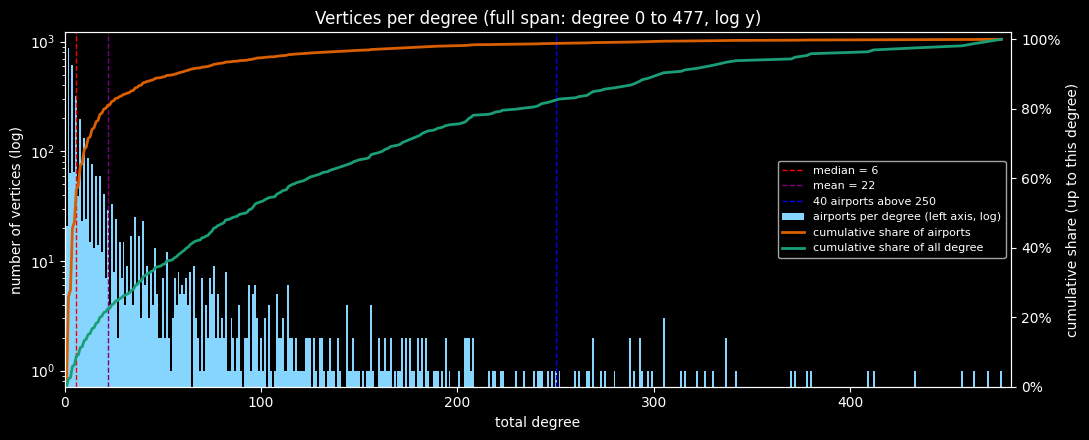

In [ ]:

full = counts.reindex(range(0, int(deg.max()) + 1), fill_value=0)

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(full.index, full.values, width=1.0, color="#86d5ff", label="airports per degree (left axis, log)")
ax.set_yscale("log")                      # log y, x unchanged
ax.set_xlim(0, deg.max() + 5)
ax.set(title=f"Vertices per degree (full span: degree 0 to {deg.max()}, log y)",
       xlabel="total degree", ylabel="number of vertices (log)")

ax.axvline(deg.median(), color="r", ls="--", lw=1, label=f"median = {deg.median():.0f}")
# ax.text(deg.median()+3, axes[0].get_ylim()[1] * 0.92, f"median {deg.median():.0f}", fontsize=8)
ax.axvline(deg.mean(), color="purple", ls="--", lw=1, label=f"mean = {deg.mean():.0f}")
# ax.text(deg.mean()+3, axes[0].get_ylim()[1] * 0.10, f"mean {deg.mean():.0f}", fontsize=8)
ax.axvline(250, color="b", ls="--", lw=1, label=f"{(deg > 250).sum()} airports above 250")
# ax.text(255, ax.get_ylim()[1] * 0.3, f"{(deg > 250).sum()} airports above 250", fontsize=9)

ax2 = ax.twinx()                          # cumulative curves, right axis (linear)
ax2.plot(cum_airports.index, cum_airports.values, color="#d95f02", lw=2, label="cumulative share of airports")
ax2.plot(cum_degree.index, cum_degree.values, color="#1b9e77", lw=2, label="cumulative share of all degree")
ax2.set_ylim(0, 1.02)
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax2.set_ylabel("cumulative share (up to this degree)")
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax2.legend(h1 + h2, l1 + l2, loc="center right", fontsize=8)

plt.tight_layout()
plt.savefig("fig_p3_degree_full_span.png", dpi=150)
plt.show()

**Takeaway:** the degree distribution is very uneven.

* The **median is 6** but the **mean is 22**. A few huge hubs pull the mean far above the typical airport.
* **25.9%** of airports have a total degree under 3. With a cut-off of 5, the share rises to **45.6%**.
  So almost half of all airports have fewer than 5 connections.
* The two cumulative curves show the gap. At degree 20, 80% of airports are already counted, but they
  hold only 21% of all degree. The top 10% of airports hold **62.7%** of all degree and the top 1% hold
  15.4%. The bottom half of the airports hold only 7.0%.
* The log-log plot shows a long tail: many small airports and a few very large hubs.
* The full bar chart confirms the tail. About 91% of airports have a total degree of 60 or less. A thin
  tail of hubs runs out to degree 477, and 40 airports lie above 250.

The bars for even degrees are taller because a two-way route adds 2 to total degree (1 in, 1 out).

---
## 8. Subgraphs: one network per airline

A **subgraph** uses some of the vertices and edges of a graph. The routes of one airline form a subgraph
of `G`.

`MG` records which airline owns each edge (the airline is the edge key). The edges of each airline are
collected, and `G.edge_subgraph(...)` builds the subgraph. For each subgraph we count airports, routes
and **weak components**. A weak component is a group that forms one piece when arrow directions are
ignored (section 9 explains this).

*Purpose:* build one subgraph per airline and rank the airlines by number of routes.

In [15]:
edges_by_airline = defaultdict(list)
for u, v, airline in MG.edges(keys=True):
    edges_by_airline[airline].append((u, v))

rows = []
for airline, edges in edges_by_airline.items():
    sub = G.edge_subgraph(edges)
    rows.append((airline, sub.number_of_nodes(), sub.number_of_edges(),
                 nx.number_weakly_connected_components(sub)))

airline_stats = (pd.DataFrame(rows, columns=["airline", "airports", "routes", "weak components"])
                 .sort_values("routes", ascending=False).reset_index(drop=True))
airline_stats.head(5)

,airline,airports,routes,weak components
0,FR,176,2484,1
1,AA,434,2354,1
2,UA,432,2180,1
3,DL,354,1981,2
4,US,352,1960,1



*Purpose:* count the airlines whose network is a single weak component, and inspect DL as an example of a
split network.


In [16]:
one_piece = (airline_stats["weak components"] == 1).sum()
print(f"Airlines whose network is one weak component: {one_piece} of {len(airline_stats)}")

dl = G.edge_subgraph(edges_by_airline["DL"])
dl_parts = sorted(nx.weakly_connected_components(dl), key=len, reverse=True)
print("DL component sizes:", [len(c) for c in dl_parts])
print("DL smaller component:", sorted(dl_parts[1]))

Airlines whose network is one weak component: 512 of 568
DL component sizes: [351, 3]
DL smaller component: ['BTS', 'KSC', 'PRG']


**Takeaway:** the biggest networks belong to FR, AA, UA, DL and US. Most airline subgraphs are weakly
connected. **DL splits into 2 components**: a small group of 3 airports (BTS, KSC and PRG) has no DL route
to the main network in this data.

---
## 9. Extra results: hubs and components

### 9.1 Top hubs
*Purpose:* rank airports by total degree and add names from `airports.dat`. The table also shows the
number of **connected airports** (distinct neighbours, the undirected degree used by Participant 1). This
is about half the total degree, because most routes are two-way.

In [17]:
ap = airports.dropna(subset=["iata"]).drop_duplicates("iata").set_index("iata")

hubs = pd.DataFrame({"total degree": deg, "connected airports": pd.Series(dict(G_und.degree()))})
hubs["name"] = ap["name"]
hubs["country"] = ap["country"]
hubs.nlargest(5, "total degree")[["name", "country", "total degree", "connected airports"]]

,name,country,total degree,connected airports
FRA,Frankfurt am Main Airport,Germany,477,244
CDG,Charles de Gaulle International Airport,France,470,240
AMS,Amsterdam Airport Schiphol,Netherlands,463,248
IST,Istanbul Airport,Turkey,457,236
ATL,Hartsfield Jackson Atlanta International Airport,United States,433,217


**Takeaway:** the top hubs are FRA (477), CDG (470), AMS (463), IST (457) and ATL (433).

### 9.2 Weak and strong components
Both ideas split a directed graph into groups of airports. They differ in how movement is allowed.

Consider a city of **one-way streets**.

* **Strong:** for any two places A and B, a driver can go from A to B **and** from B to A while obeying
  every sign. Detours and roundabouts are allowed, so a long way back still counts.
* **Weak:** if the signs are ignored, the city may still be one connected piece. Then it is weakly
  connected.
* **The gap:** some places can be entered but never left, or the reverse. They are connected, but only
  in one direction.

**Two-airport test.** For two airports X and Y:

* *Strong test:* can a traveller fly from X to Y **and** from Y to X, with any number of stops?
* *Weak test:* does any path exist between them if flight direction is **ignored**?

The **number of stops does not matter**. Only the existence of a route counts.

Every strong component lies inside one weak component. So the number of strong components is at least the
number of weak components.

*Purpose (toy example):* illustrate both ideas on four airports. A and B fly both ways. B flies to C. D
flies to C.

In [18]:
toy = nx.DiGraph([("A", "B"), ("B", "A"), ("B", "C"), ("D", "C")])
print("Weak:  ", sorted(sorted(c) for c in nx.weakly_connected_components(toy)))
print("Strong:", sorted(sorted(c) for c in nx.strongly_connected_components(toy)))

Weak:   [['A', 'B', 'C', 'D']]
Strong: [['A', 'B'], ['C'], ['D']]


**Takeaway:** A and B form one strong component, while C and D are each alone. All four airports form one
weak component.

*Purpose (toy picture):* draw the toy graph. The left panel keeps the arrows and colours each **strong**
component. The right panel removes the arrows to show the **weak** view.

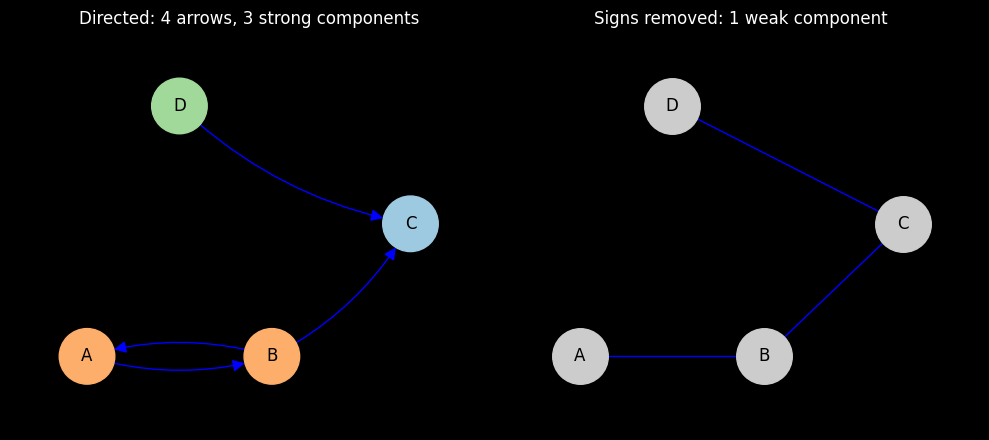

In [ ]:
pos = {"A": (-0.8, 0), "B": (0.4, 0), "C": (1.3, 0.9), "D": (-0.2, 1.7)}
strong_toy = list(nx.strongly_connected_components(toy))
palette = ["#9ecae1", "#fdae6b", "#a1d99b", "#dadaeb"]
node_color = {v: palette[k] for k, comp in enumerate(strong_toy) for v in comp}

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

nx.draw_networkx(toy, pos, ax=axes[0], node_color=[node_color[v] for v in toy], node_size=1600,
                 edge_color="b", arrows=True, arrowsize=18, connectionstyle="arc3,rad=0.15")                #changed edge color here cause i cant see the arrrows on black bg
axes[0].set_title(f"Directed: {toy.number_of_edges()} arrows, {len(strong_toy)} strong components")

U = toy.to_undirected()
nx.draw_networkx(U, pos, ax=axes[1], node_color="#cccccc", node_size=1600, edge_color="b",)               #changed edge color here cause i cant see the arrrows on black bg
axes[1].set_title(f"Signs removed: {nx.number_weakly_connected_components(toy)} weak component")

for ax in axes:
    ax.set_xlim(-1.3, 1.8)
    ax.set_ylim(-0.5, 2.2)
    ax.axis("off")
plt.tight_layout()
plt.show()

**Takeaway:** in the right picture, all four airports are linked once directions are ignored, so there is
**1 weak component**. In the left picture, the arrows allow no return from C, and no airport can reach D.
So there are **3 strong components**: {A, B}, {C} and {D}.

*Purpose (real data):* count both kinds of component in `G` and compare their sizes.

In [20]:
weak = sorted(nx.weakly_connected_components(G), key=len, reverse=True)
strong = sorted(nx.strongly_connected_components(G), key=len, reverse=True)

print("Weak components:  ", len(weak), "| sizes:", [len(c) for c in weak])
print("Strong components:", len(strong), "| 10 largest sizes:", [len(c) for c in strong[:10]])
print("Strong components with a single airport:", sum(len(c) == 1 for c in strong))
print("Airports outside the largest strong component:", G.number_of_nodes() - len(strong[0]))

Weak components:   8 | sizes: [3397, 10, 4, 4, 4, 2, 2, 2]
Strong components: 44 | 10 largest sizes: [3354, 10, 8, 4, 4, 4, 2, 2, 2, 1]
Strong components with a single airport: 35
Airports outside the largest strong component: 71


**Takeaway:**

* **8 weak components.** One giant group of 3,397 airports, plus 7 small groups (2 to 10 airports) that
  have no link to it at all in this data.
* **44 strong components.** One giant core of 3,354 airports, where a traveller can fly between any two
  with any number of stops. The other 43 are small. 35 of them have a single airport. Of those, 23 are
  **one-way traps**: the 7 start-only and 16 end-only airports from section 3.3. A traveller can leave
  but not return, or arrive but not leave.

71 airports sit outside the core. Not all of them are dead ends. Only the 23 one-way traps are start-only
or end-only. The other airports outside the core have both incoming and outgoing flights, but they are
not part of the core's two-way loop.

The directed model shows this. An undirected view would hide it, because it treats every link as
two-way. These airports would then look like part of the main network.

### 9.3 Isolated subgraphs
An **isolated subgraph** here means a **weak component** with no link to the rest of the network, in
either direction. No flight enters it from outside, and none leaves it.

`G` has 8 weak components: one giant group (3,397 airports) and 7 small groups (sizes 10, 4, 4, 4, 2, 2,
2). `G` has **no isolated single airports** (total degree 0). Every vertex comes from a route row, so each
airport has at least one arc. The minimum total degree is 1.

*Purpose:* list the 7 small groups in one compact table, with airport codes and countries only. The
`weak` list from 9.2 and `ap` from 9.1 are reused.

In [21]:
rows = []
for k, comp in enumerate(weak[1:], start=1):
    countries = sorted({ap["country"][c] for c in comp if c in ap.index})
    rows.append((k, len(comp), " ".join(sorted(comp)), ", ".join(countries) or "not listed"))

small_groups = pd.DataFrame(rows, columns=["group", "size", "airports", "country (where listed)"]).set_index("group")
display(small_groups)
print(f"Airports in small groups: {sum(len(c) for c in weak[1:])} | minimum total degree in G: {deg.min()}")

,size,airports,country (where listed)
group,,,
1,10,BMY GEA ILP KNQ KOC LIF MEE TGJ TOU UVE,New Caledonia
2,4,AKB DUT IKO KQA,United States
3,4,BFI CLM ESD FRD,United States
4,4,ERS MPA NDU OND,Namibia
5,2,SPB SSB,Virgin Islands
6,2,BLD GCW,not listed
7,2,CKX TKJ,United States


Airports in small groups: 28 | minimum total degree in G: 1


**Takeaway:** small isolated groups exist in the data, but there are no isolated single airports. The
main network is one connected giant. The largest small group has 10 airports and is listed in New
Caledonia. The other six groups have only 2 to 4 airports each.

---
## 10. Original versus processed graph

### 10.1 What cleaning changed
*Purpose:* compare the graphs before and after cleaning, step by step. The first table is the cleaning log
with counts before and after each step. The second table compares the raw graph (with the self-loop) with
the cleaned graph.

In [22]:
cleaning_log = pd.DataFrame(log, columns=["step", "unit", "before", "after", "vertices before", "vertices after"])
cleaning_log["change"] = cleaning_log["after"] - cleaning_log["before"]
display(cleaning_log.set_index("step"))

items = [
    ("MG edges", before["MG edges"], MG.number_of_edges()),
    ("G edges", before["G edges"], G.number_of_edges()),
    ("vertices", before["vertices"], G.number_of_nodes()),
    (f"total degree of {loop_node}", before["loop degree"], G.degree(loop_node)),
    ("density of G (%)", round(100 * before["density"], 5), round(100 * nx.density(G), 5)),
    ("self-loops in G", len(loops_g), nx.number_of_selfloops(G)),
]
compare_clean = pd.DataFrame([(k, x, y, round(y - x, 5)) for k, x, y in items],
                             columns=["item", "raw (with self-loop)", "cleaned", "change"],
                             dtype=object).set_index("item")
compare_clean

,unit,before,after,vertices before,vertices after,change
step,,,,,,
1.1 drop rows with missing keys,rows,67663,67663,3425,3425,0
1.1 drop rows with invalid codes,rows,67663,67663,3425,3425,0
1.1 drop duplicate rows,rows,67663,67663,3425,3425,0
2 merge parallel edges (MG to G),edges,67663,37595,3425,3425,-30068
5 remove self-loops (MG),edges,67663,67662,3425,3425,-1
5 remove self-loops (G),edges,37595,37594,3425,3425,-1


,raw (with self-loop),cleaned,change
item,,,
MG edges,67663,67662,-1
G edges,37595,37594,-1
vertices,3425,3425,0
total degree of PKN,14,12,-2
density of G (%),0.32058,0.32057,-0.00001
self-loops in G,1,0,-1



**Takeaway:** the checks in section 1 find nothing to drop. The merge of parallel edges is a modelling
step, so it is not a loss of data. The self-loop removal is the only cleaning step that changes the graph.
It removes one edge from each graph and lowers the total degree of PKN from 14 to 12. No vertex is lost
and the density does not visibly change.


### 10.2 What if low-degree airports were also removed?
Section 7.2 showed that 25.9% of airports have a total degree under 3. Removing them could reduce noise,
so the effect needs a test.

Pruning changes degree, centrality and component results. It can also remove real structure, such as
small airports and rare links. For this reason the test runs on a **copy** of `G`, and `G` itself is not
changed.

*Purpose:* measure the effect of pruning on a copy of `G`.

In [23]:
low = [v for v, d in G.degree() if d < 3]
P = G.copy()
P.remove_nodes_from(low)

def summary(g):
    return {"vertices": g.number_of_nodes(), "edges": g.number_of_edges(),
            "weak components": nx.number_weakly_connected_components(g),
            "strong components": nx.number_strongly_connected_components(g)}

compare_low = pd.DataFrame({"G (kept)": summary(G), "G without low-degree": summary(P)})
compare_low["change"] = compare_low["G without low-degree"] - compare_low["G (kept)"]
display(compare_low)

changed = {v: (G.degree(v), P.degree(v)) for v in P if G.degree(v) != P.degree(v)}
top = sorted(changed.items(), key=lambda kv: kv[1][0] - kv[1][1], reverse=True)[:3]
print(f"Remaining airports that lose connections: {len(changed)}")
print("Largest drops (degree before, after):", top)

,G (kept),G without low-degree,change
vertices,3425,2537,-888
edges,37594,35892,-1702
weak components,8,5,-3
strong components,44,14,-30


Remaining airports that lose connections: 364
Largest drops (degree before, after): [('BOG', (148, 120)), ('HND', (147, 119)), ('DEN', (337, 309))]


**Takeaway:** pruning removes 888 airports and 1,702 arcs. It also lowers the degree of 364 remaining
airports, for example BOG (148 to 120). Weak components drop from 8 to 5, and strong components drop from
44 to 14.

*Purpose:* check whether pruning **splits the giant group** or leaves **isolated pieces**. Each removed
airport is traced to its original group, and each small component of `P` is traced back to its source.

In [24]:
wb = sorted(nx.weakly_connected_components(G), key=len, reverse=True)
wa = sorted(nx.weakly_connected_components(P), key=len, reverse=True)

# 1. sizes before and after
print(f"Weak components before: {len(wb)} | sizes: {[len(c) for c in wb]}")
print(f"Weak components after:  {len(wa)} | sizes: {[len(c) for c in wa]}")

# 2. where did the removed airports sit?
origin = {v: (0 if k == 0 else k) for k, comp in enumerate(wb) for v in comp}   # 0 = giant, 1..7 = small groups
low_set = set(low)
rm_giant = sum(origin[v] == 0 for v in low_set)
rm_small = len(low_set) - rm_giant
print(f"\nLow-degree airports removed: {len(low_set)} | from giant: {rm_giant} | from small groups: {rm_small}")

# 3. size check
print(f"Giant before - removed in giant = {len(wb[0])} - {rm_giant} = {len(wb[0]) - rm_giant} | giant after = {len(wa[0])}"
      f" | equal: {len(wb[0]) - rm_giant == len(wa[0])}")

def label(v):
    return "giant" if origin[v] == 0 else f"small group {origin[v]} (size {len(wb[origin[v]])})"

# 4. every small component of P and where it came from
print("\nSmall components after pruning:")
for k, comp in enumerate(wa[1:], start=1):
    print(f"  Component {k}: size {len(comp)} | airports {sorted(comp)} | came from: {sorted({label(v) for v in comp})}")

# 5. single-airport components
singles = [next(iter(c)) for c in wa if len(c) == 1]
print(f"\nSingle-airport components in P: {len(singles)}")
for v in singles:
    g_nb = sorted(set(G.successors(v)) | set(G.predecessors(v)))
    print(f"  {v}: came from {label(v)} | neighbours in G: {g_nb} | removed neighbours: {[u for u in g_nb if u in low_set]}")

Weak components before: 8 | sizes: [3397, 10, 4, 4, 4, 2, 2, 2]
Weak components after:  5 | sizes: [2526, 6, 3, 1, 1]

Low-degree airports removed: 888 | from giant: 871 | from small groups: 17
Giant before - removed in giant = 3397 - 871 = 2526 | giant after = 2526 | equal: True

Small components after pruning:
  Component 1: size 6 | airports ['BMY', 'GEA', 'KOC', 'LIF', 'TGJ', 'UVE'] | came from: ['small group 1 (size 10)']
  Component 2: size 3 | airports ['ERS', 'MPA', 'NDU'] | came from: ['small group 4 (size 4)']
  Component 3: size 1 | airports ['DUT'] | came from: ['small group 2 (size 4)']
  Component 4: size 1 | airports ['BFI'] | came from: ['small group 3 (size 4)']

Single-airport components in P: 2
  DUT: came from small group 2 (size 4) | neighbours in G: ['AKB', 'IKO', 'KQA'] | removed neighbours: ['AKB', 'IKO', 'KQA']
  BFI: came from small group 3 (size 4) | neighbours in G: ['CLM', 'ESD', 'FRD'] | removed neighbours: ['CLM', 'ESD', 'FRD']


**Takeaway:**

* Pruning does **not** split the giant group into pieces. It only shrinks it, from 3,397 to 2,526. The
  size check holds: 3,397 minus the 871 removed equals 2,526.
* It shrinks or deletes the small isolated groups. 17 of the 28 airports in small groups are removed.
  The 10-airport group drops to 6 and one 4-airport group drops to 3. Three small groups disappear
  completely (the three 2-airport groups).
* It leaves **single stranded airports**. DUT and BFI are the two size-1 components. Step 5 confirms they
  are leftovers of small groups (the Aleutian group and the Puget Sound group). All their neighbours were
  low-degree airports, so all of them were removed.
* This is the cost: the small isolated structure that matters for a disruption study is lost.


*Purpose:* test whether the key results hold on both graphs. A result that changes a lot after pruning is
not robust to the pruning choice.


In [25]:

def key_results(g):
    d = pd.Series(dict(g.degree()))
    reciprocal = sum(1 for a, b in g.edges if g.has_edge(b, a)) / g.number_of_edges()
    return {
        "vertices": g.number_of_nodes(),
        "arcs": g.number_of_edges(),
        "density (%)": round(100 * nx.density(g), 3),
        "median total degree": d.median(),
        "mean total degree": round(d.mean(), 1),
        "arcs with a return arc (%)": round(100 * reciprocal, 1),
        "top 5 hubs": " ".join(d.nlargest(5).index),
    }

robust = pd.DataFrame({"G (cleaned)": key_results(G), "P (pruned)": key_results(P)})
display(robust)

top20_g = set(deg.nlargest(20).index)
top20_p = set(pd.Series(dict(P.degree())).nlargest(20).index)
print(f"Top 20 hubs shared by G and P: {len(top20_g & top20_p)} of 20")


,G (cleaned),P (pruned)
vertices,3425,2537
arcs,37594,35892
density (%),0.321,0.558
median total degree,6.0,8.0
mean total degree,22.0,28.3
arcs with a return arc (%),97.6,98.0
top 5 hubs,FRA CDG AMS IST ATL,FRA CDG AMS IST ATL


Top 20 hubs shared by G and P: 20 of 20



**Takeaway:** the hub ranking is robust. The top 5 hubs are the same, and all of the top 20 hubs stay in
the top 20. Other results are not robust. The vertex count falls from 3,425 to 2,537. The density rises
from 0.32% to 0.56%, the median total degree rises from 6 to 8 and the mean from 22.0 to 28.3. These
changes come from the removal itself and not from the data, so pruned figures would overstate how
connected a typical airport is.


**Decision:** we do **not** remove low-degree airports.

* They are real airports. Pruning would delete 888 of 3,425.
* The removal also cuts the degree of 364 other airports (for example BOG). This distorts the degree
  statistics, although the top hubs keep their ranking.
* It erases small groups and leaves stranded single airports. Weak components drop from 8 to 5 and strong
  components from 44 to 14. Two airports are left alone, with no link to anything.
* The robustness check shows that density and the degree statistics change a lot (density 0.32% to
  0.56%, median degree 6 to 8). They would depend on the pruning choice.

The project asks about hubs, bridges and disruption. Small airports that depend on one hub are exactly
the ones that lose service when that hub fails. So the **only cleaning step that changes the graph is the
removal of the self-loop**. The merge of parallel edges is a modelling step and keeps every airline.

### 10.3 Key numbers of the final graph

| Item | Value |
|---|---|
| Vertices (airports) | 3,425 |
| Edges in `MG` / `G` | 67,662 / 37,594 |
| Two-way pairs / one-way arcs | 18,338 / 918 |
| Undirected edges | 19,256 |
| Density of `G` | 0.32% |
| Median total degree | 6 |
| Weak / strong components | 8 / 44 |

---
## 11. Hand-over
`G` (simple, directed, 3,425 airports, 37,594 arcs) and `MG` (airline as edge key) are clean and ready.
The next notebooks can use them to study hubs, bridges and disruption.

**Coverage of topics and learning outcome**

| Topic or outcome | Section |
|---|---|
| Simple, multi and mixed graphs | 3 |
| Directed versus undirected graphs | 4 |
| Self-loops | 5 |
| Vertex degree and the handshaking theorem | 6, 7.2 |
| Adjacency matrix and graph density | 7.1 |
| Subgraphs | 8, 9.3 |
| Weak and strong connectivity | 9.2 |
| How the cleaned graph is built | 1, 2, 5 |
| Size, density and degree distribution | 2, 7, 10.3 |
| Justification of each cleaning decision | 1.1, 5, 10 |

**References**
* OpenFlights data: https://openflights.org/data.php (ODbL)
* Rosen, K. H. *Discrete Mathematics and Its Applications*, chapter "Graphs".